In [1]:
import empiricaldist
import janitor
import matplotlib.pyplot as plt
import numpy as np
import palmerpenguins
import pandas as pd
import scipy.stats
import seaborn as sns
import sklearn.metrics
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats as ss
import session_info

In [2]:
%matplotlib inline
sns.set_style(style='whitegrid')
sns.set_context(context='notebook')
plt.rcParams['figure.figsize'] = (11, 9.4)

penguin_color = {
    'Adelie': '#ff6602ff',
    'Gentoo': '#0f7175ff',
    'Chinstrap': '#c65dc9ff'
}

In [3]:
preprocessed_penguins_df = sns.load_dataset("penguins") #Datos preprocesados
processed_penguins_df= preprocessed_penguins_df.dropna()

In [ ]:
#Grafica de puntos

sns.scatterplot(data=processed_penguins_df, x='bill_length_mm', y='bill_depth_mm', alpha=1/2, s=100) #La "s" es para la cantidad de puntos
sns.displot(processed_penguins_df, x='bill_length_mm', y='bill_depth_mm', rug= True) #rug es para poner un indicador en el eje de los datos
sns.displot(processed_penguins_df, x='bill_length_mm', y='bill_depth_mm', kind= "kde", rug = True) #kind= "kde" para hacer un grafico combinado con la densidad
sns.jointplot(processed_penguins_df, x='bill_length_mm', y='bill_depth_mm') #Grafico de dispersion combinado con un histograma

In [ ]:
#Gráficos de violín y boxplots

sns.scatterplot(processed_penguins_df, x= "species", y="flipper_length_mm", hue= "species", palette= penguin_color)
sns.stripplot(data=processed_penguins_df, x='species', y='flipper_length_mm', palette=penguin_color)

ax = sns.boxplot(data=processed_penguins_df, x='flipper_length_mm', y='species', palette=penguin_color, whis=np.inf)
ax = sns.stripplot(data=processed_penguins_df, x='flipper_length_mm', y='species', color='.3') #Para hacer un boxplot y agregar los puntos

ax = sns.violinplot(data=processed_penguins_df, x='species', y='flipper_length_mm', color='.8')
ax = sns.stripplot(data=processed_penguins_df, x='species', y='flipper_length_mm', palette=penguin_color) #Hacer un grafico de violin y agregar los puntos

sns.swarmplot(data=processed_penguins_df, x='species', y='flipper_length_mm', hue='species', palette=penguin_color) #Grafico para contar los datos en una determinada posicion

C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_12488\706378810.py:3: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  processed_penguins_df.corr()
C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_12488\706378810.py:5: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(processed_penguins_df.corr(), center= 0, vmin= -1, vmax= 1, linewidths= 0.5, annot= True,
C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_12488\706378810.py:8: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sn

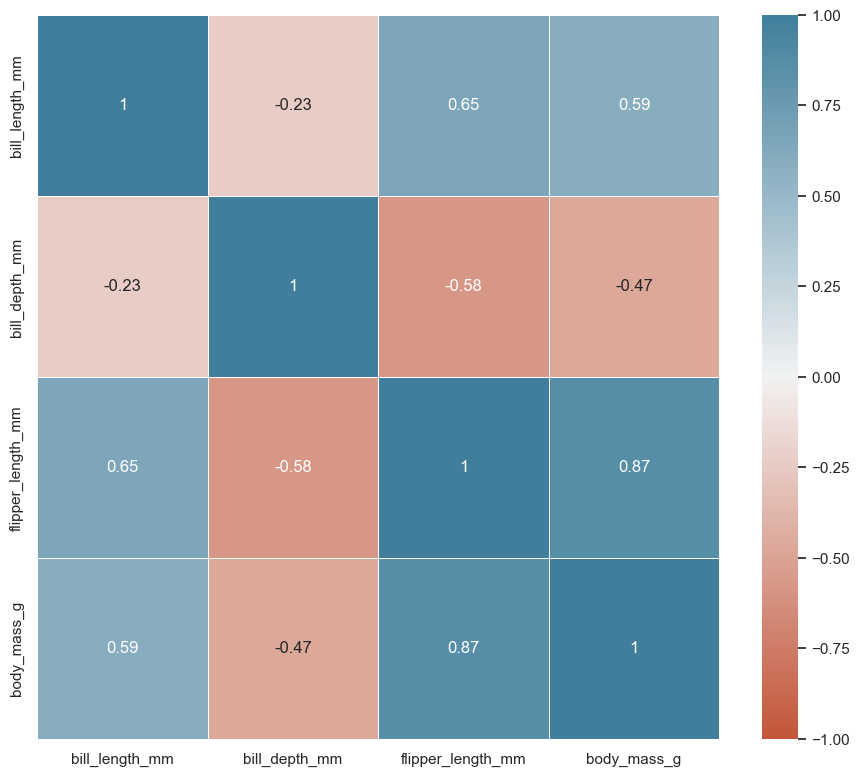

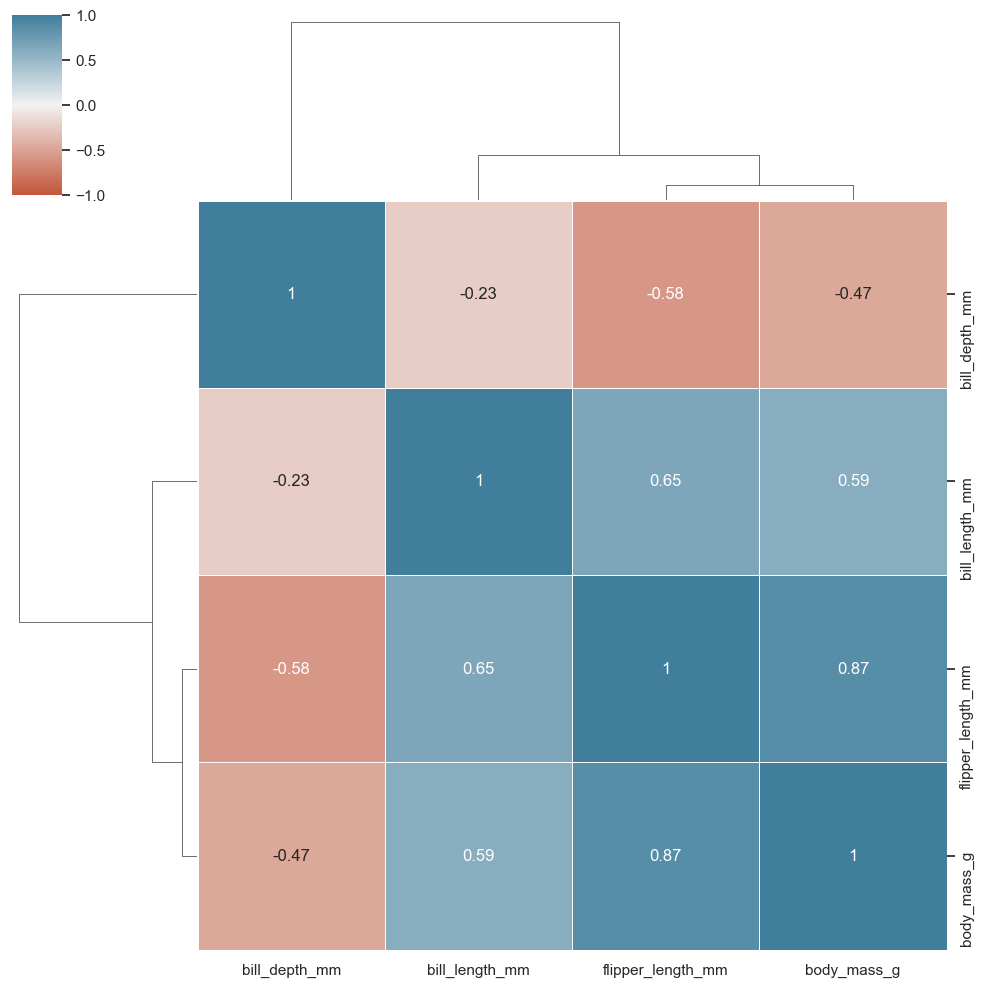

In [28]:
#Matrices de correlacion

processed_penguins_df.corr()

sns.heatmap(processed_penguins_df.corr(), center= 0, vmin= -1, vmax= 1, linewidths= 0.5, annot= True, 
            cmap=sns.diverging_palette(20, 230, as_cmap=True)) #El ultimo argumento es para poner colores divergentes

sns.clustermap(processed_penguins_df.corr(), center= 0, vmin= -1, vmax= 1, linewidths= 0.5, annot= True, 
            cmap=sns.diverging_palette(20, 230, as_cmap=True)) #Crear una grafica de cluster con las correlaciones

In [4]:
#Analisis de regresion simple

x= processed_penguins_df["body_mass_g"].values
y= processed_penguins_df["flipper_length_mm"].values

mod1= scipy.stats.linregress(x=x, y=y) # pendiente, la intersección, el coeficiente de correlación, el valor p y el error estándar
print(mod1)

#sns.lmplot(data= processed_penguins_df, x= "body_mass_g", y= "flipper_length_mm", height= 10) #Visualizar la linea que proporciona la grafica

smf.ols(formula= "flipper_length_mm ~ body_mass_g", data= processed_penguins_df).fit().params #Crear y analizar un modelo

smf.ols(formula= "flipper_length_mm ~ body_mass_g", data= processed_penguins_df).fit().summary() #Resumen y estadisticas del modelo

LinregressResult(slope=0.015195264815217668, intercept=137.03962089225467, rvalue=0.8729788985653611, pvalue=3.1328362509724443e-105, stderr=0.00046665391049053483, intercept_stderr=1.998769429024315)


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      flipper_length_mm   R-squared:                       0.762
Model:                            OLS   Adj. R-squared:                  0.761
Method:                 Least Squares   F-statistic:                     1060.
Date:                Wed, 20 Mar 2024   Prob (F-statistic):          3.13e-105
Time:                        10:52:28   Log-Likelihood:                -1112.1
No. Observations:                 333   AIC:                             2228.
Df Residuals:                     331   BIC:                             2236.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     137.0396      1.999     68.562      0.000     133.108     140.972
body_mass_g     0.0152      0.000     32.562      0.000       0.014       0.016
==============================================================================
Omnibus:                       11.941   Durbin-Watson:                   1.641
Prob(Omnibus):                  0.003   Jarque-Bera (JB):               12.696
Skew:                          -0.474   Prob(JB):                      0.00175
Kurtosis:                       2.872   Cond. No.                     2.28e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.28e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""